In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:

df = pd.read_csv('market_cl.csv')

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:

df['Total_Spending'] = (
    df['MntWines'] +
    df['MntFruits'] +
    df['MntMeatProducts'] +
    df['MntFishProducts'] +
    df['MntSweetProducts'] +
    df['MntGoldProds']
)

df = df.dropna(subset=['Income'])

X = df[['Income', 'Total_Spending']]


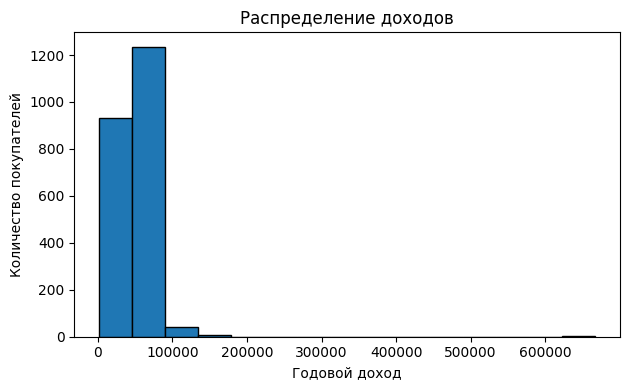

In [5]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(X['Income'], bins=15, edgecolor='black')
plt.title('Распределение доходов')
plt.xlabel('Годовой доход')
plt.ylabel('Количество покупателей')

plt.tight_layout()
plt.show()


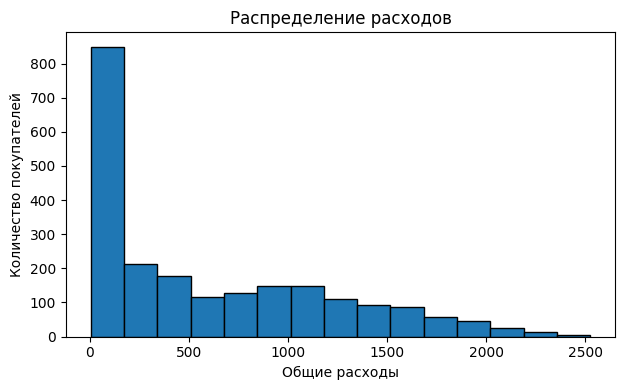

In [6]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 2)
plt.hist(X['Total_Spending'], bins=15, edgecolor='black')
plt.title('Распределение расходов')
plt.xlabel('Общие расходы')
plt.ylabel('Количество покупателей')

plt.tight_layout()
plt.show()


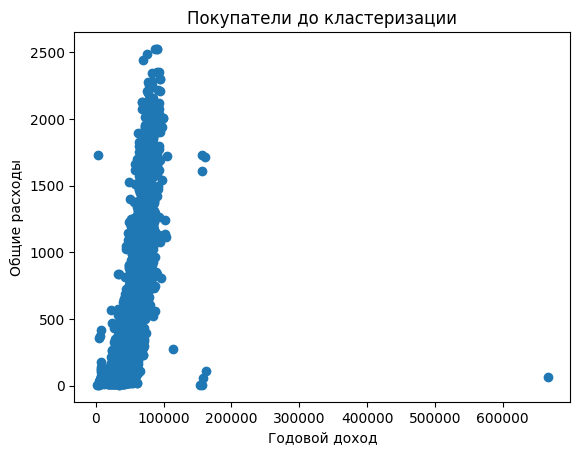

In [7]:

plt.scatter(X.iloc[:, 0], X.iloc[:, 1])

plt.xlabel('Годовой доход')
plt.ylabel('Общие расходы')
plt.title('Покупатели до кластеризации')

plt.show()


In [8]:

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans.fit(X)
labels = kmeans.labels_


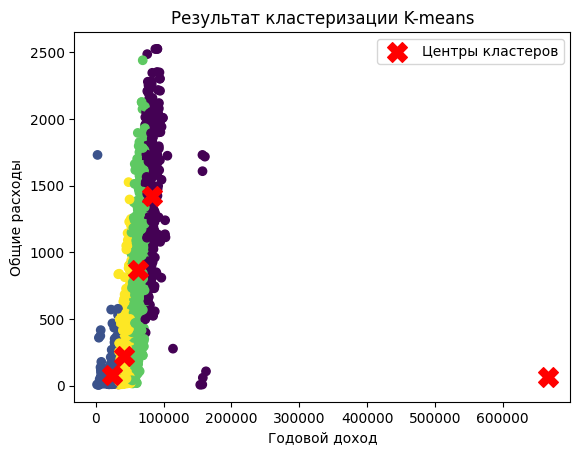

In [9]:

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=labels,
    cmap='viridis'
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Центры кластеров'
)

plt.xlabel('Годовой доход')
plt.ylabel('Общие расходы')
plt.title('Результат кластеризации K-means')
plt.legend()

plt.show()


In [10]:

df['Cluster'] = labels

print(df[['ID', 'Income',
          'Total_Spending', 'Cluster']].head(10))


     ID   Income  Total_Spending  Cluster
0  5524  58138.0            1617        3
1  2174  46344.0              27        4
2  4141  71613.0             776        3
3  6182  26646.0              53        1
4  5324  58293.0             422        3
5  7446  62513.0             716        3
6   965  55635.0             590        3
7  6177  33454.0             169        4
8  4855  30351.0              46        1
9  5899   5648.0              49        1


In [11]:

from sklearn.metrics import silhouette_score

score_before = silhouette_score(X, labels)

print('Silhouette Score без нормализации:',
      round(score_before, 3))


Silhouette Score без нормализации: 0.53


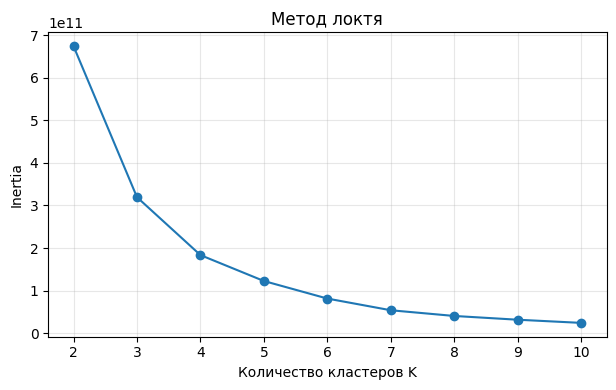

In [12]:

inertia = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_k = model.fit_predict(X)

    inertia.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X, labels_k)
    )

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertia, marker='o')
plt.xlabel('Количество кластеров K')
plt.ylabel('Inertia')
plt.title('Метод локтя')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


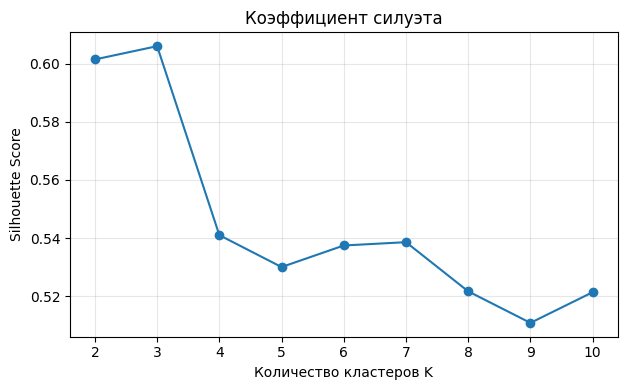

K = 2, Silhouette Score = 0.601
K = 3, Silhouette Score = 0.606
K = 4, Silhouette Score = 0.541
K = 5, Silhouette Score = 0.530
K = 6, Silhouette Score = 0.537
K = 7, Silhouette Score = 0.539
K = 8, Silhouette Score = 0.522
K = 9, Silhouette Score = 0.511
K = 10, Silhouette Score = 0.521


In [13]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette_scores, marker='o')
plt.xlabel('Количество кластеров K')
plt.ylabel('Silhouette Score')
plt.title('Коэффициент силуэта')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

for k, score in zip(k_values, silhouette_scores):
    print(f'K = {k}, Silhouette Score = {score:.3f}')


In [14]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print('Первые 5 строк после нормализации:')
print(X_scaled[:5])


Первые 5 строк после нормализации:
[[ 0.2340627   1.67548812]
 [-0.23455948 -0.96235832]
 [ 0.76947764  0.28024985]
 [-1.01723878 -0.91922372]
 [ 0.24022146 -0.30704427]]


In [15]:

kmeans_scaled = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels_scaled = kmeans_scaled.fit_predict(X_scaled)

score_after = silhouette_score(X_scaled, labels_scaled)

print('Silhouette Score после нормализации:',
      round(score_after, 3))


Silhouette Score после нормализации: 0.444


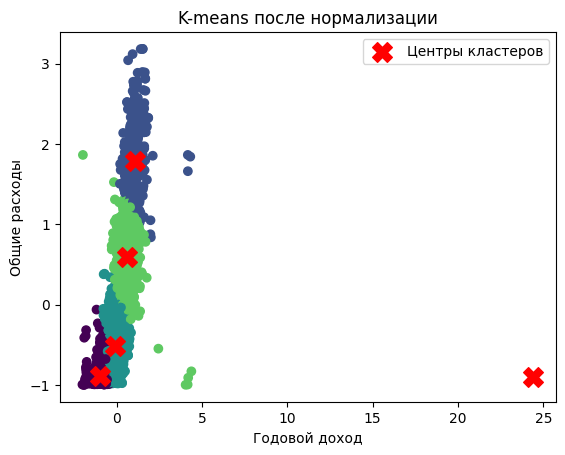

In [16]:

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_scaled,
    cmap='viridis'
)

plt.scatter(
    kmeans_scaled.cluster_centers_[:, 0],
    kmeans_scaled.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Центры кластеров'
)

plt.xlabel('Годовой доход')
plt.ylabel('Общие расходы')
plt.title('K-means после нормализации')
plt.legend()

plt.show()
